In [1]:
import torch as tc
import numpy as np
import qutip as qt
import pandas as pd
#from scipy.sparse import csr_array, lil_array
import matplotlib.pyplot as plt
import torch.nn as nn
#import time as tm
#from torch.func import jacrev, vmap
from tqdm import tqdm
import sys
from typing import List
import os
sys.path.insert(0, '../src/')
import function as my

device = tc.device('cuda' if tc.cuda.is_available() else 'cpu')
print(f"Executing in device: {device}")

if device.type == 'cpu':
  num_threads = 10
  tc.set_num_threads(num_threads)
  tc.set_num_interop_threads(num_threads)
  print(f"Threads set to: {tc.get_num_threads()}")

Executing in device: cpu
Threads set to: 10


In [2]:
loaded = False# Set True to load control fields from a file
FouFeat = True# Whether or not to use Fourier features
sig = 0.05
nval = 2
filesctrl = "../../data_files/Control/StchKr_Had_1noi.csv"
Liedim = 3#Dimension of the Lie-algebra
nist = 7# NUmber of initial states
Nfield=3# Number of control fields
Nedo= Liedim*nist# Number of differential equations to solve
Ncoll = 2#Number of collapse operators

In [3]:
if loaded:
  loadedfields = pd.read_csv(filesctrl)

  t_points =  loadedfields.iloc[::2,0].to_numpy()
  dt = t_points[1]-t_points[0]
  t_points = t_points - 0.5*dt*np.ones_like(t_points)
  tfinal      = t_points[-1] + dt
  t_points = np.concatenate([t_points, np.array([tfinal])])
  N           = len(t_points)

  ctrls = loadedfields.iloc[::2,1:4].to_numpy()
  ctrls = np.concatenate([ctrls, np.zeros((1,Nfield))], axis=0)
  ctrls[-1,:] = 1.5*ctrls[-2,:] - 0.5*ctrls[-3,:]
else:
  tfinal = 2.#2.52*np.pi
  N = 501#Number of collocation points

  def Field(t):
      return ( 1.5* np.sin(2.0 * t) - 0.3*np.cos(3* t - 0.5) + 0.4*np.sin(7.0 * t)
          )*np.sin(np.pi*t/tfinal)**2

  t_points = np.linspace(0., tfinal, N)

  ctrls = np.zeros((len(t_points), Nfield))

  ctrls[:,0] = Field(t_points)
  if (Nfield > 1):
    ctrls[:,1] = np.cos(np.pi*t_points/tfinal)
    if (Nfield > 2):
        ctrls[:,2] = 0.5*(-1 + np.sin(np.pi*t_points/tfinal))
  #ctrls[:,1] = -0.5 * np.ones_like(t_points)


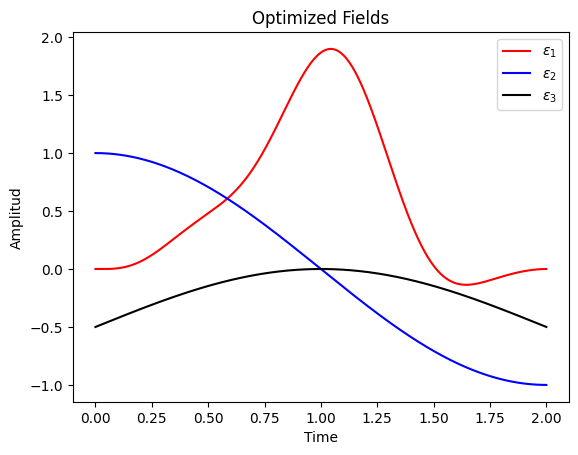

In [4]:
colors = ['r', 'b', 'k']
fig, ax = plt.subplots()

for i in range(Nfield):
  ax.plot(t_points, ctrls[:,i], label=fr"$\epsilon_{i+1}$", color=colors[i])
  

plt.xlabel('Time')
plt.ylabel('Amplitud')
plt.legend()
plt.title('Optimized Fields')
plt.show()

In [4]:
def inv_sigmoid(y):
    eps = 1e-6
    y = tc.clamp(y, eps, 1 - eps)
    return tc.log(y / (1 - y))

class FourierFeatures(nn.Module):
    # Uncomment the following code to use uniform frequency distribution and comment the code below it
    """
    def __init__(self, n_freq, f_max, trainable=True):
        super().__init__()
        self.f_max = f_max
        self.raw_freq = nn.Parameter(tc.randn(n_freq), requires_grad=trainable)

        f0 = tc.linspace(0.05 * f_max, 0.95 * f_max, n_freq)
        raw0 = inv_sigmoid(f0 / f_max)

        self.raw_freq = nn.Parameter(raw0.clone(), requires_grad=trainable)

    def get_freq(self):
        return self.f_max * tc.sigmoid(self.raw_freq)

    def forward(self, t):
        if t.dim() == 1:
            t = t.unsqueeze(1)   # (batch,1)

        freq = self.get_freq().unsqueeze(0)   # (1,n_freq)
        arg = 2.0 * np.pi * t * freq        # (batch,n_freq)

        return tc.cat([tc.sin(arg), tc.cos(arg)], dim=1)
    """
    def __init__(self, m, sigma=10.0, trainable=False):
        super().__init__()
        B = tc.randn(m, 1) * sigma
        self.B = nn.Parameter(B, requires_grad=trainable)

    def forward(self, t):
        if t.dim() == 1:
            t = t[:, None]
        x = 2 * np.pi * t @ self.B.T
        return tc.cat([tc.sin(x), tc.cos(x)], dim=-1)
    
class Rede(nn.Module):
    def __init__(self, neuronio, activation, input_=1, output_=1,
                 creat_p=False, N_of_paramater=1, dropout_prob=0.0,
                 use_fourier=False, n_freq=32, f_max=10.0, trainable=True):
        super().__init__()

        self.neuronio = neuronio
        self.output = output_
        self.creat_p = creat_p
        self.N_of_paramater = N_of_paramater
        self.dropout_prob = dropout_prob
        self.use_fourier = use_fourier

        if use_fourier:
            #self.ff = FourierFeatures(n_freq=n_freq, f_max=f_max, trainable=True)
            self.ff = FourierFeatures(m=n_freq, sigma=f_max, trainable=trainable)
            first_in = 2 * n_freq
        else:
            self.ff = None
            first_in = input_

        self.hidden_layers = nn.ModuleList([nn.Linear(first_in, neuronio[0])])
        self.hidden_layers.extend(
            [nn.Linear(neuronio[_], neuronio[_+1]) for _ in range(len(neuronio)-1)]
        )
        self.output_layer = nn.Linear(neuronio[-1], output_)

        self.activation_ = activation
        self.dropouts = nn.ModuleList([nn.Dropout(dropout_prob) for _ in range(len(neuronio))])

        if creat_p:
            self.parametro = nn.Parameter(tc.rand(N_of_paramater)**2)

    def forward(self, x):
        if self.ff is not None:
            x = self.ff(x)

        for layer, activation, dropout in zip(self.hidden_layers, self.activation_, self.dropouts):
            x = activation(layer(x))
            x = dropout(x)

        x = self.output_layer(x)
        return x
    
class SIN(tc.nn.Module):
    def __init__(self):
        super(SIN, self).__init__()
    def forward(self, x):
        return tc.sin(x)

In [5]:
if FouFeat:
        neuronio = [128, 128]

        X_vector = Rede(
        neuronio=neuronio,
        input_=1,
        output_=Nedo + Nfield,
        activation=[SIN()]*len(neuronio),
        creat_p=True,
        N_of_paramater=Ncoll,
        use_fourier=True,
        n_freq=12,
        f_max=1.0,
        trainable=False
        )

        opt = tc.optim.Adam(X_vector.parameters(),
                lr = 0.001)
        time =  tc.linspace(
                0,
                tfinal,
                N,
                dtype   = tc.float32,
                requires_grad = True).reshape((-1, 1))
else:
        neuronio = [256, 256]#[128,128,128] didn't work
        X_vector   = Rede(
        neuronio    = neuronio,
        input_      = 1,
        output_     = Nedo+Nfield,
        activation  =[tc.nn.Tanh()]*len(neuronio),
        creat_p     =True,
        N_of_paramater= Ncoll)
        opt = tc.optim.Adam(X_vector.parameters(),
                lr = 0.001)
        time =  tc.linspace(
                0,
                tfinal,
                N,
                dtype   = tc.float32,
                requires_grad = True).reshape((-1, 1))
        #index_data = np.random.randint(0,N,size=100)
        #X_vector.parametro

In [6]:
Instates = []
np.random.seed(42)  # Set a random seed for reproducibility

for _ in range(nist+nval):
    p = np.ones(3)
    while(np.sum(p*p) > 1.):
        p = np.random.uniform(-1., 1., 3)
        rho0 = qt.Qobj(0.5*np.array([[1.+p[2], p[0]-1j*p[1]],[p[0]+1j*p[1], 1.-p[2]]]))
    Instates.append(rho0)

Sz = 0
gams = [0.3, 0.5]#Decay rates for the Lindblad operators
basis = [qt.sigmax(), qt.sigmay(), qt.sigmaz()]
# The full Hamiltonian is defined as a list: 
H = [basis[2]*Sz]
for i in range(Nfield):
    H.append([basis[i], ctrls[:, i]]) # QuTiP uses cubic spline interpolation for field_data
c_ops = [np.sqrt(gams[0])*qt.sigmaz(), np.sqrt(gams[1])*qt.sigmam()]
opts = {'store_states':True, 'atol':1.e-8, 'rtol':1.e-6}
Obsdat = []
# Define the set of initial states
for i in range(len(Instates)):
    result = qt.mesolve(H, rho0=Instates[i], tlist=t_points, e_ops=basis, c_ops=c_ops, options=opts)
    Obsdat.append(result.expect)

Obsdat = np.array(Obsdat[:nist]).reshape(Nedo, N).T
Obsdat += sig * np.random.randn(*Obsdat.shape)  # Add Gaussian noise to the observations
Odata = tc.tensor(Obsdat, dtype=time.dtype)

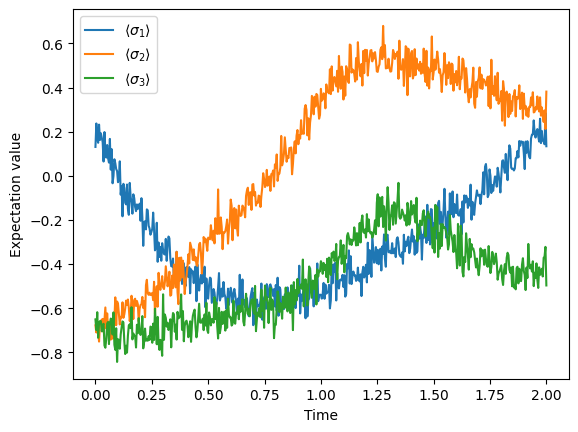

In [9]:
#colors = ['r', 'g', 'b']
fig, ax = plt.subplots()
for i in range(Liedim):
  ax.plot(t_points, Obsdat[:,i], label=fr"$\langle \sigma_{i+1} \rangle$")
  #ax.plot(t_points, Obsdat1[0][i], label=fr"$\langle \sigma_{i+1} \rangle$, high decay", linestyle='--', color=colors[i])

ax.set_xlabel("Time")
ax.set_ylabel("Expectation value")
ax.legend()
plt.show()

In [7]:
commcoeff = tc.zeros(Liedim, Liedim, Liedim, dtype=time.dtype)

commcoeff[0,1,2] = -2
commcoeff[2,0,1] = -2
commcoeff[1,2,0] = -2
commcoeff[1,0,2] = 2
commcoeff[0,2,1] = 2
commcoeff[2,1,0] = 2
collcoef = tc.zeros(Ncoll, Liedim, Liedim, dtype=time.dtype)
#L_0 = \sigma_z
collcoef[0, 0, 0] = -2
collcoef[0, 1, 1] = -2
#L_1 = \sigma_-
collcoef[1, 0, 0] = -0.5
collcoef[1, 1, 1] = -0.5
collcoef[1, 2, 2] = -1
cnstcoef = tc.zeros(Ncoll, Liedim, dtype=time.dtype)
cnstcoef[1, 2] = -1

In [8]:
NUM_OBSERVAVEIS = 3
NUM_CAMPOS = 3
NUM_ESTADOS = nist
IDX_DIVISAO_CAMPOS = NUM_ESTADOS * NUM_OBSERVAVEIS
"""
# Rede 1: Aprende as trajetórias dos observáveis
Rede_Estados = Rede(
    neuronio=[128, 128, 128],
    input_=1,
    output_=NUM_ESTADOS * NUM_OBSERVAVEIS,
    activation=[SIN()]*3,
    creat_p=True,
    N_of_paramater=0,
    use_fourier=True,
    n_freq=16,
    f_max=3.0
).to(device)
"""
Rede_Estados = my.Rede(
    neuronio    = neuronio,
    input_      = 1,
    output_     = NUM_ESTADOS * NUM_OBSERVAVEIS,
    activation  =[tc.nn.Tanh()]*len(neuronio),
    creat_p     =True,
    N_of_paramater= 0).to(device)


In [9]:
# Rede 2: Aprende apenas os campos de controle
neuronio = [128, 128, 128]

Rede_Campos = Rede(
    neuronio=neuronio,
    input_=1,
    output_=NUM_CAMPOS,
    activation=[SIN()]*3,
    creat_p=False,    
    use_fourier=True,
    n_freq=10,
    f_max=1.0
).to(device)
"""
Rede_Campos = my.Rede(
    neuronio    = neuronio,
    input_      = 1,
    output_     = NUM_CAMPOS,
    activation  =[tc.nn.Tanh()]*len(neuronio),
    creat_p     =True,
    N_of_paramater= 0).to(device)
"""
#I try with an architechture without Fourier features, since the fields are expected to be smooth functions of time
time =  tc.linspace(
        0,
        t_points[-1],
        len(t_points),
        dtype   = tc.float32,
        #requires_grad = True,
        device=device).reshape((-1, 1))

In [10]:
print("Computing derivatives from a neural network for the observables.")

opt_observables = tc.optim.Adam(Rede_Estados.parameters(), lr=1e-3)
scheduler_obs = tc.optim.lr_scheduler.ReduceLROnPlateau(opt_observables, mode='min', factor=0.5, patience=500)

best_val_loss = float("inf")
best_state = None
early_stop_patience = 500
epochs_without_improvement = 0
min_delta = 1e-8

#Split into training and validation sets to avoid overfitting noisy data
n_val = int(N * 0.3)
n_train = N - n_val

idx = np.arange(N)

np.random.shuffle(idx)# This function shuffles the indices of the data points.
idx_train = tc.as_tensor(idx[:n_train], dtype=tc.long, device=device)
idx_val   = tc.as_tensor(idx[n_train:], dtype=tc.long, device=device)
times_train = time[idx_train]
times_val   = time[idx_val]
times_train = times_train.detach()
times_val = times_val.detach()
LOSS_TRAIN = []
LOSS_VAL = []
#opt_ids = {id(p) for g in opt_observables.param_groups for p in g["params"]}
#model_ids = {id(p) for p in Rede_Estados.parameters()}
#print(len(opt_ids), len(model_ids), opt_ids == model_ids)
#print(opt_observables.param_groups[0]["lr"])
#common = opt_ids & model_ids
#print("shared:", len(common))
#for name, p in Rede_Estados.named_parameters():
#    print(name, tuple(p.shape), id(p) in opt_ids)
#opt_ids = {id(p) for g in opt_observables.param_groups for p in g["params"]}
#for name, obj in list(globals().items()):
#    if isinstance(obj, nn.Module):
#        ids = {id(p) for p in obj.parameters()}
#        print(name, len(ids), len(ids & opt_ids))
for epoca in range(500):
    Rede_Estados.train()
    opt_observables.zero_grad()
    y_pred = Rede_Estados(times_train)
    loss_estados = 0.0
    for estado_idx in range(NUM_ESTADOS):
        idx_start = estado_idx * NUM_OBSERVAVEIS
        idx_end = idx_start + NUM_OBSERVAVEIS
        y_cond = Odata[idx_train, 3*estado_idx:3*estado_idx+3]
        y_pred_cond = y_pred[:, idx_start:idx_end]
        loss_estados += ((y_pred_cond - y_cond) ** 2).mean()
    loss_estados /= NUM_ESTADOS
    LOSS_TRAIN.append(loss_estados.item())
    loss_estados.backward()
    #grads = [
    #    p.grad.detach().flatten()
    #    for p in Rede_Estados.parameters()
    #    if p.grad is not None
    #]
    #grad_norm = tc.cat(grads).norm(p=2) if grads else tc.tensor(0.0)
    #print(grad_norm.item())
    #params_before = [
    #    p.detach().clone()
    #    for p in Rede_Estados.parameters()
    #]
    opt_observables.step()
    #max_update = max(
    #    (p.detach() - p0).abs().max().item()
    #    for p, p0 in zip(Rede_Estados.parameters(), params_before)
    #    if p.numel() > 0
    #)
    #print("loss:", loss_estados.item(), "max update:", max_update)
    Rede_Estados.eval()
    #Early stopping using validation loss.
    with tc.no_grad():
        y_val_pred = Rede_Estados(times_val)
        loss_val = 0.0
        for estado_idx in range(NUM_ESTADOS):
            idx_start = estado_idx * NUM_OBSERVAVEIS
            idx_end = idx_start + NUM_OBSERVAVEIS
            y_val_cond = Odata[idx_val, 3*estado_idx:3*estado_idx+3]
            y_val_pred_cond = y_val_pred[:, idx_start:idx_end]
            loss_val += ((y_val_pred_cond - y_val_cond) ** 2).mean()
        loss_val /= NUM_ESTADOS
    val_value = loss_val.item()
    LOSS_VAL.append(val_value)
    if val_value < best_val_loss - min_delta:
        best_val_loss = val_value
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in Rede_Estados.state_dict().items()
        }
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
    if epochs_without_improvement >= early_stop_patience:
        print(f"Early stopping at epoch {epoca}; best validation loss = {best_val_loss:.3e}")
        break
    scheduler_obs.step(loss_val)
    #scheduler_obs.step(loss_estados)
    if (epoca + 1) % 500 == 0:
        print(f"Epoch {epoca+1} | Loss Estados: {loss_val.item():.2e}")
Rede_Estados.load_state_dict(best_state)
Rede_Estados.train()
time_grad = time.detach().clone().requires_grad_(True)
y_fixo = Rede_Estados(time_grad)
dX_dt_fixo = tc.cat([
    tc.autograd.grad(
        outputs=y_fixo[:, j],
        inputs=time_grad,
        grad_outputs=tc.ones_like(y_fixo[:, j]),
        create_graph=False,
        retain_graph=True
    )[0]
    for j in range(y_fixo.shape[1])
], dim=1)
y_fixo_np = y_fixo.detach().cpu().numpy()
dX_dt_fixo_np = dX_dt_fixo.detach().cpu().numpy()

Computing derivatives from a neural network for the observables.
Epoch 500 | Loss Estados: 2.80e-03


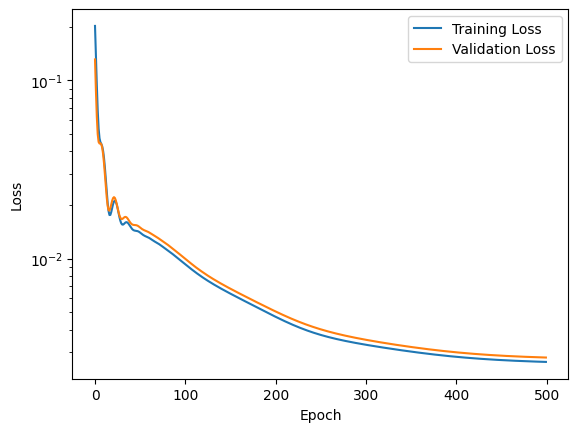

In [11]:
plt.plot(LOSS_TRAIN, label='Training Loss')
plt.plot(LOSS_VAL, label='Validation Loss')
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

[]

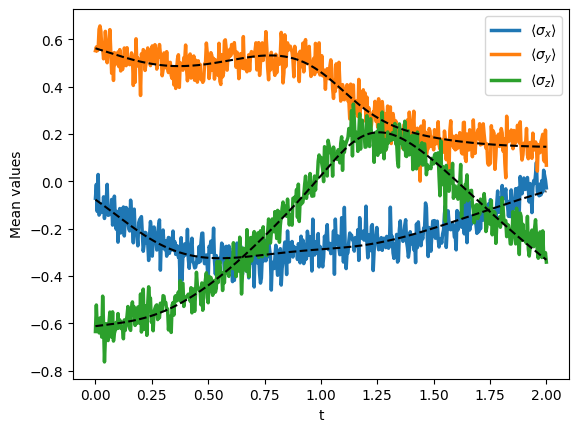

In [12]:
istate = 4 

fig, ax = plt.subplots()

ax.plot(t_points, Obsdat[:, 3*istate], label=fr"$\langle \sigma_x \rangle$", lw=2.5)
ax.plot(t_points, Obsdat[:, 3*istate+1], label=fr"$\langle \sigma_y  \rangle$", lw=2.5)
ax.plot(t_points, Obsdat[:, 3*istate+2], label=fr"$\langle \sigma_z \rangle$", lw=2.5)
for i in range(3):
    ax.plot(t_points, y_fixo_np[:, istate * NUM_OBSERVAVEIS + i], 'k--')

ax.set_xlabel("t")
ax.set_ylabel("Mean values")
ax.legend()
plt.plot()

if a.shape = [n, m, l] and b.shape = [m, j],
torch.tensordot(a, b, dims = ([1], [0]))
produces a tensor of shape [n, l, j], where each element is computed by summing over the specified index/indices.

if a.shape = [n, m, l] and b.shape = [n, l, j],
torch.bmm(a, b)
produces a tensor of shape [n, m, j], where the n-th element in the 1st index is computed as the matrix multiplication of the matrices in the n-th index of a and b.

In [14]:
def calculate_physics_loss(commcoeff: tc.Tensor, collcoef: tc.Tensor, cnstcoef: tc.Tensor, Gammas: tc.Tensor, Obs: tc.Tensor, derivs: tc.Tensor, Jt: List[tc.Tensor]):
    dim = 3
    #print(f"Jt.shape = {Jt.shape}, derivs.shape = {derivs.shape}, Obs.shape = {Obs.shape}, commcoeff.shape = {commcoeff.shape}, collcoeff.shape = {collcoef.shape}, cnstcoef.shape = {cnstcoef.shape}, Gammas.shape = {Gammas.shape}" )
    #-----Calculate the matrix corresponding to the right-hand side of the EDOs----------------
    A = tc.tensordot(Jt, commcoeff, dims=([1], [0]))    
    A += tc.tensordot(Gammas, collcoef, dims=([0], [0]))

    b = Gammas @ cnstcoef
    b = b.repeat(Jt.shape[0], 1)
    
    rhs_vec = tc.zeros_like(derivs)
    
    ax = tc.bmm(A, Obs[:, 0:3].unsqueeze(-1)).squeeze(-1)
    ax += b
    rhs_vec[:, 0:3] = ax
    # Residual squared, summed over all components
    loss_edo = ((derivs - rhs_vec)**2).mean()
    
    return loss_edo

Starting optimization of a neural network for the fields, keeping the driving frequency equal to zero.
y_fixo False None
dX_dt_fixo False None
time False None
param_qutip False None


  0%|                                                  | 0/1000 [00:00<?, ?it/s]/home/martin/miniconda3/lib/python3.13/site-packages/torch/optim/lr_scheduler.py:1694: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  current = float(metrics)
100%|██████████████████████████████████████| 1000/1000 [00:06<00:00, 156.23it/s]


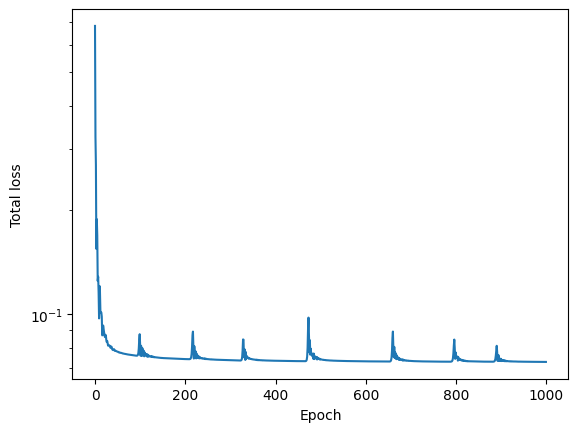

In [15]:
print("Starting optimization of a neural network for the fields, keeping the driving frequency equal to zero.")
y_fixo = y_fixo.detach()
#time = time.detach().requires_grad_(True)
opt_campos = tc.optim.Adam(Rede_Campos.parameters(), lr=5e-3)
scheduler_cam = tc.optim.lr_scheduler.ReduceLROnPlateau(opt_campos, mode='min', factor=0.5, patience=200)

param_qutip = tc.tensor([0.0, 0.0], device=device)
#param_qutip = Rede_Campos.parametro

LOSS = []

for n, t in [("y_fixo", y_fixo), ("dX_dt_fixo", dX_dt_fixo), ("time", time), ("param_qutip", param_qutip)]:
    print(n, t.requires_grad, t.grad_fn)

for epoca in tqdm(range(1000)):
    opt_campos.zero_grad()
    
    # Rede de campos prevê J(t)
    z = Rede_Campos(time)
    j_fields = [z[:, i:i+1] for i in range(NUM_CAMPOS)]
    j_fields = tc.stack(j_fields)
    j_fields = j_fields.squeeze(-1)
    j_fields = j_fields.T

    loss_edo = 0.0
    for estado_idx in range(NUM_ESTADOS):
        idx_start = estado_idx * NUM_OBSERVAVEIS
        idx_end = idx_start + NUM_OBSERVAVEIS

        y_cond = y_fixo[:, idx_start:idx_end]
        dX_dt_cond = dX_dt_fixo[:, idx_start:idx_end]
        #Consider taking param_qutip**2 if negative values are explored
        residuos = calculate_physics_loss(commcoeff, collcoef, cnstcoef, param_qutip, y_cond, dX_dt_cond, j_fields)
        loss_edo += residuos.mean()

    loss_edo /= NUM_ESTADOS
    """
    dz = tc.cat([
        tc.autograd.grad(
            outputs=z[:, j],
            inputs=time_grad,
            grad_outputs=tc.ones_like(z[:, j]),
            create_graph=False,
            retain_graph=True
        )[0]
        for j in range(z.shape[1])
    ], dim=1)
    """
    loss_endpts = ((j_fields[0,:] - tc.from_numpy(ctrls[0,:]))**2).mean() + ((j_fields[-1,:] - tc.from_numpy(ctrls[-1,:]))**2).mean()
    loss_total = loss_edo + 0.5*loss_endpts#

    loss_total.backward()
    opt_campos.step()
    scheduler_cam.step(loss_total)

    LOSS.append(loss_total.item())
    #if (epoca + 1) % 500 == 0:
    #    print(f"Época {epoca+1} | Loss EDO: {loss_total.item():.2e}")

plt.plot(LOSS)
plt.yscale('log')
plt.xlabel("Epoch")
plt.ylabel("Total loss")
plt.show()

[0. 0.]


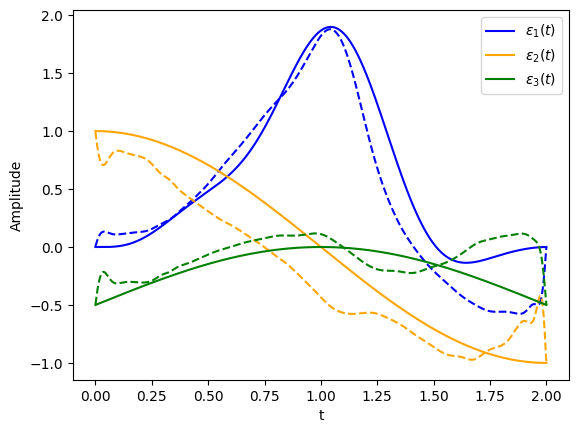

In [18]:
X_=Rede_Campos(time).cpu().detach().numpy()

fig, ax = plt.subplots()
ax.plot(t_points, ctrls[:, 0], "b", label=fr"$\epsilon_1(t)$")
ax.plot(t_points, X_[:,0],"b--")
ax.plot(t_points, ctrls[:, 1], color="orange", label=fr"$\epsilon_2(t)$")
ax.plot(t_points, X_[:,1], "--", color="orange")
ax.plot(t_points, ctrls[:, 2], color="g", label=fr"$\epsilon_3(t)$")
ax.plot(t_points, X_[:,2],"g--")

ax.set_xlabel("t")
ax.set_ylabel("Amplitude")
ax.legend()

print(param_qutip.detach().cpu().numpy())

In [19]:
# ==============================================================================
# FASE 3A: Otimizar APENAS os Gammas (Rede_Campos CONGELADA)
# ==============================================================================
param_gamma = tc.nn.Parameter(tc.tensor([1.0, 1.0], device=device))

opt_gamma = tc.optim.Adam([param_gamma], lr=1e-2)

print("Fase 3A: Ajustando APENAS os Gammas (Rede_Campos congelada)...")
for epoca in range(600):
    opt_gamma.zero_grad()
    
    #gammas_positivos = tc.nn.functional.softplus(param_gamma)
    
    # Avalia a Rede_Campos sem calcular gradientes para ela
    with tc.no_grad():
        z = Rede_Campos(time)
        j_fields = [z[:, i:i+1] for i in range(NUM_CAMPOS)]
        j_fields = tc.stack(j_fields)
        j_fields = j_fields.squeeze(-1)
        j_fields = j_fields.T

    loss_edo = 0.0
    for estado_idx in range(NUM_ESTADOS):
        idx_start = estado_idx * NUM_OBSERVAVEIS
        idx_end = idx_start + NUM_OBSERVAVEIS

        y_cond = y_fixo[:, idx_start:idx_end]
        dX_dt_cond = dX_dt_fixo[:, idx_start:idx_end]

        residuos = calculate_physics_loss(commcoeff, collcoef, cnstcoef, param_gamma, y_cond, dX_dt_cond, j_fields)
        loss_edo += residuos.mean()

    loss_edo /= NUM_ESTADOS
    
    # Perda Total com Regularização L1 nos Gammas
    loss_total = loss_edo
    
    loss_total.backward()
    opt_gamma.step()

    if (epoca + 1) % 200 == 0:
        g_est = (param_gamma).detach().cpu().numpy()#tc.nn.functional.softplus(param_gamma).detach().cpu().numpy()
        print(f"Época {epoca+1} | Loss EDO: {loss_edo.item():.2e} | Gammas Estimados: {np.round(g_est, 5)}")

Fase 3A: Ajustando APENAS os Gammas (Rede_Campos congelada)...
Época 200 | Loss EDO: 3.35e-02 | Gammas Estimados: [0.25769 0.23639]
Época 400 | Loss EDO: 3.35e-02 | Gammas Estimados: [0.25875 0.23545]
Época 600 | Loss EDO: 3.35e-02 | Gammas Estimados: [0.25875 0.23545]


In [36]:
# ==============================================================================
# FASE 3B: Refinamento Concomitante Fino (Campos + Gammas)
# ==============================================================================
tc.autograd.set_detect_anomaly(True)
opt_conjunto = tc.optim.Adam([
    {'params': Rede_Campos.parameters(), 'lr': 5e-5}, # LR reduzido para proteger os campos
    {'params': [param_gamma],            'lr': 5e-3}
])
LOSS = []
LOSS_EDO = []
LOSS_AUX = []
print("\nFase 3B: Otimização Concomitante Final...")
time = time.detach().requires_grad_(True)

print(time.grad_fn)
print(loss_edo.grad_fn)


for epoca in tqdm(range(5000)):
    opt_conjunto.zero_grad()
    
    #gammas_positivos = tc.nn.functional.softplus(param_gamma)
    z = Rede_Campos(time)
    j_fields = [z[:, i:i+1] for i in range(NUM_CAMPOS)]
    j_fields = tc.stack(j_fields)
    j_fields = j_fields.squeeze(-1)
    j_fields = j_fields.T

    loss_edo = 0.0
    for estado_idx in range(NUM_ESTADOS):
        idx_start = estado_idx * NUM_OBSERVAVEIS
        idx_end = idx_start + NUM_OBSERVAVEIS

        y_cond = y_fixo[:, idx_start:idx_end]
        dX_dt_cond = dX_dt_fixo[:, idx_start:idx_end]

        residuos = calculate_physics_loss(commcoeff, collcoef, cnstcoef, param_gamma, y_cond, dX_dt_cond, j_fields)
        loss_edo += residuos.mean()

    loss_edo /= NUM_ESTADOS
    
    loss_endpts = ((j_fields[0,:] - tc.from_numpy(ctrls[0,:]))**2).mean() + ((j_fields[-1,:] - tc.from_numpy(ctrls[-1,:]))**2).mean()
    loss_total = loss_edo + 0.5*loss_endpts 
    
    loss_total.backward()
    opt_conjunto.step()

    LOSS.append(loss_total.item())
    LOSS_EDO.append(loss_edo.item())
    #if (epoca + 1) % 500 == 0:
    #    g_est = param_gamma.detach().cpu().numpy()
    #    print(f"Época {epoca+1} | Loss EDO: {loss_edo.item():.2e} | Gammas Estimados: {np.round(g_est, 5)}")


Fase 3B: Otimização Concomitante Final...
None


100%|███████████████████████████████████████| 5000/5000 [05:31<00:00, 15.07it/s]


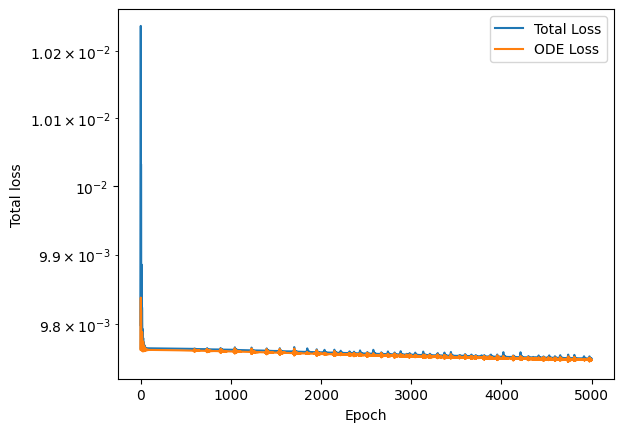

In [37]:
plt.plot(LOSS, label='Total Loss')
plt.plot(LOSS_EDO, label='ODE Loss')
plt.yscale('log')
plt.xlabel("Epoch")
plt.ylabel("Total loss")
plt.legend()
plt.show()

Optimized decay rates:  [0.3019278  0.50376207]


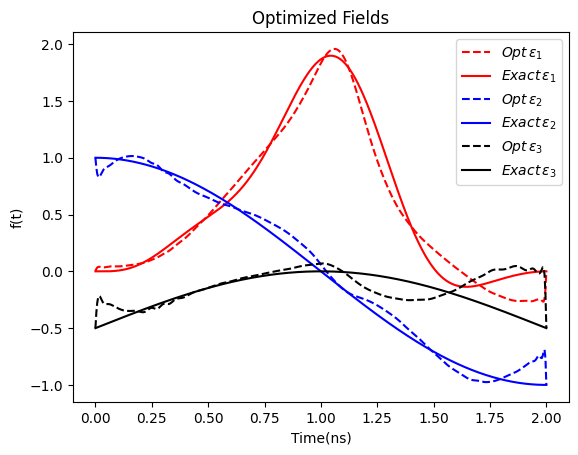

In [38]:
X_  = Rede_Campos(time).detach().numpy()
Opt_gammas = param_gamma.detach().cpu().numpy()
print("Optimized decay rates: ", Opt_gammas)

gam_opt = (X_vector.parametro).detach().numpy()
colors = ['r', 'b', 'k']
fig, ax = plt.subplots()

for i in range(Nfield):
  ax.plot(t_points, X_[:,i], label=fr"$Opt \, \epsilon_{i+1}$", color=colors[i], linestyle='--')
  ax.plot(t_points, ctrls[:,i], label=fr"$Exact \, \epsilon_{i+1}$", color=colors[i])
  

plt.xlabel('Time(ns)')
plt.ylabel('f(t)')
#plt.plot(t_points, guess_field(time).detach().numpy(),"b-", label="Guess field")
plt.legend()
plt.title('Optimized Fields')
plt.show()

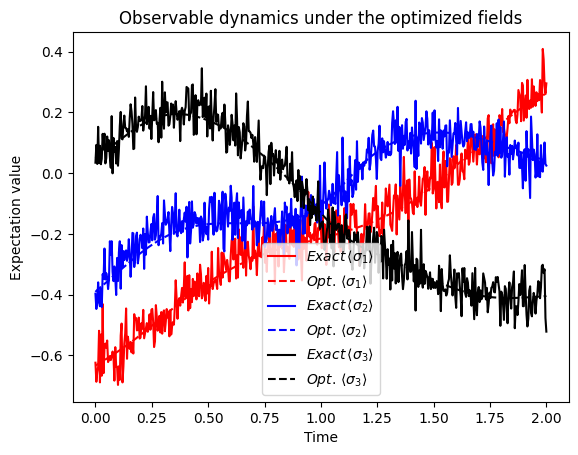

In [32]:
istate = 1

rho0 = Instates[istate]

H = [basis[2]*Sz]
for i in range(Nfield):
    H.append([basis[i], X_[:, i]]) # QuTiP uses cubic spline interpolation for field_data

c_ops = [np.sqrt(Opt_gammas[0])*qt.sigmaz(), np.sqrt(Opt_gammas[1])*qt.sigmam()]

opts = {'store_states':True, 'atol':1.e-8, 'rtol':1.e-6}
result_opt = qt.mesolve(H, rho0, t_points, e_ops=basis, c_ops=c_ops, options=opts)

fig, ax = plt.subplots()
for i in range(Liedim):
  ax.plot(t_points, Obsdat[:, Liedim*istate + i].flatten(), label=fr"$Exact \, \langle \sigma_{i+1} \rangle$", color=colors[i])
  ax.plot(t_points, result_opt.expect[i], label=fr"$Opt. \, \langle \sigma_{i+1} \rangle$", color=colors[i], linestyle='--')

ax.set_xlabel("Time")
ax.set_ylabel("Expectation value")
ax.legend()
plt.title('Observable dynamics under the optimized fields')
plt.show()